In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")
print("Current folder:", os.getcwd())


Libraries imported successfully!
Current folder: C:\Users\sanaa\OneDrive\Desktop\OIBSIP\Data Analytics-Task1-Retail Sales EDA


In [3]:

df = pd.read_csv("Dataset/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:

# Display dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows:
0


In [5]:

print("Descriptive Statistics:")
display(df.describe())

print("\nMean Total Amount:", df["Total Amount"].mean())
print("Median Total Amount:", df["Total Amount"].median())
print("Mode Total Amount:", df["Total Amount"].mode()[0])
print("Standard Deviation:", df["Total Amount"].std())


Descriptive Statistics:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Mean Total Amount: 456.0
Median Total Amount: 135.0
Mode Total Amount: 50
Standard Deviation: 559.997631555123


In [6]:

df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()

print("Monthly sales calculated successfully!")
display(monthly_sales)


Monthly sales calculated successfully!


Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

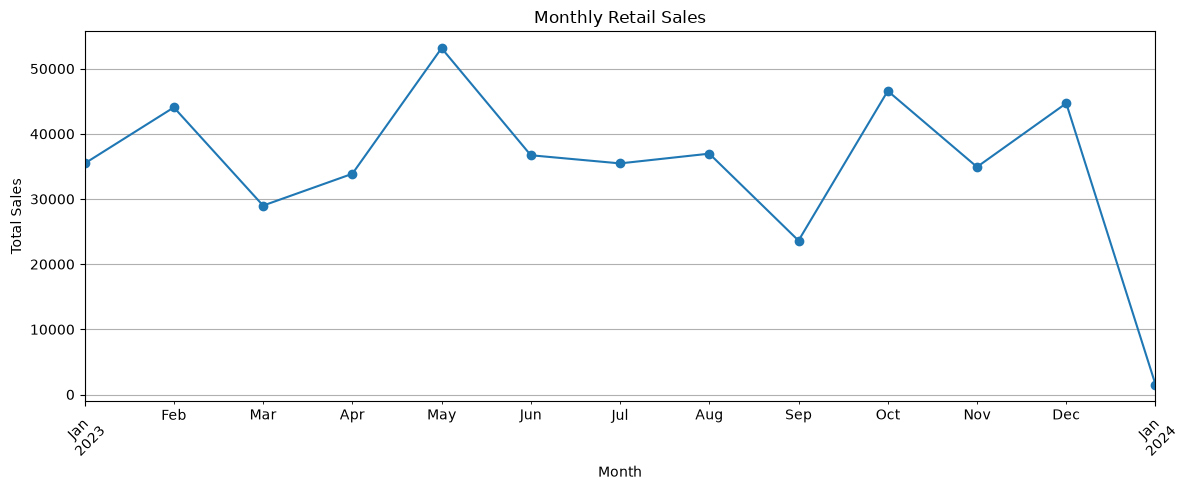

In [7]:

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()



### Observation: Monthly Sales

The monthly sales chart shows how total retail sales change over time. It helps identify months with higher and lower sales and supports better inventory and promotional planning.


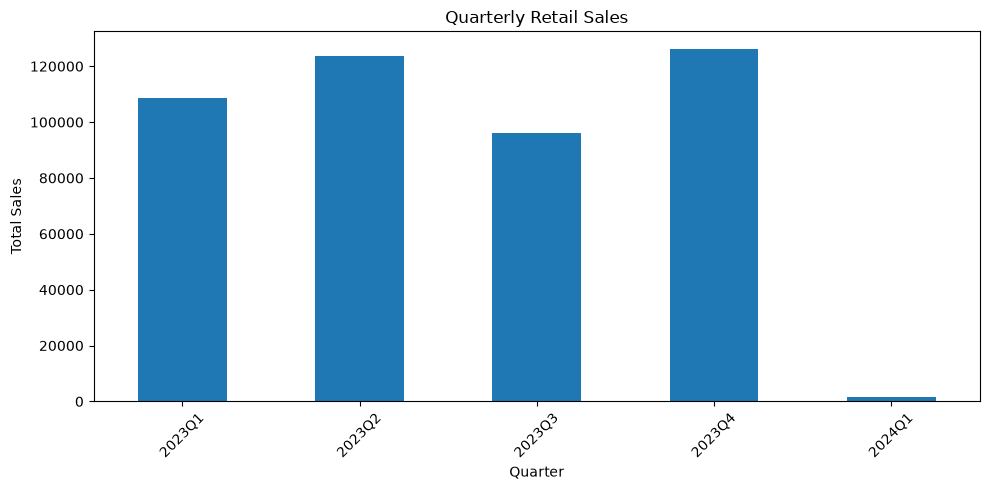

In [8]:

df["Quarter"] = df["Date"].dt.to_period("Q")
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="bar")
plt.title("Quarterly Retail Sales")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


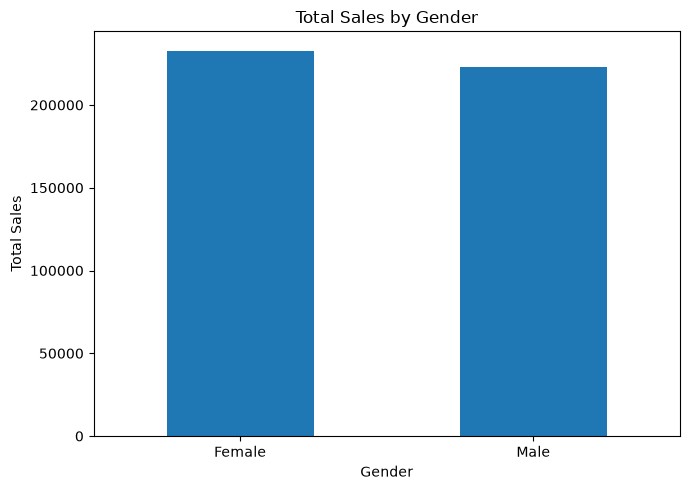

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

In [9]:

gender_sales = df.groupby("Gender")["Total Amount"].sum()

plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(gender_sales)


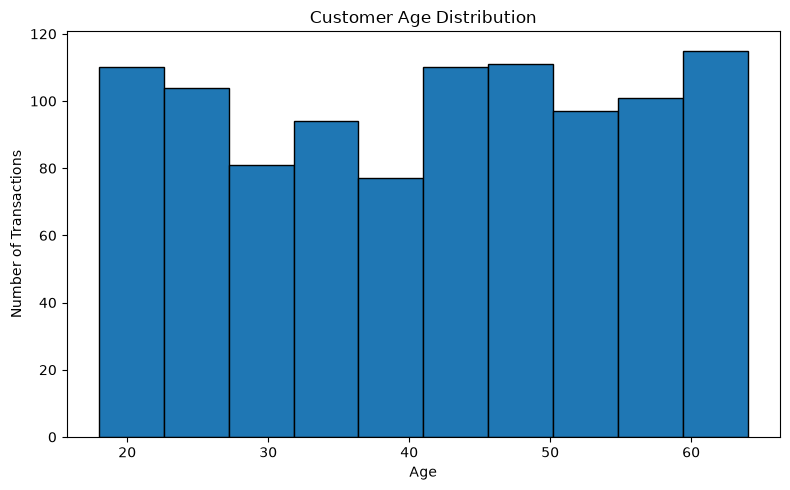

In [10]:

plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=10, edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


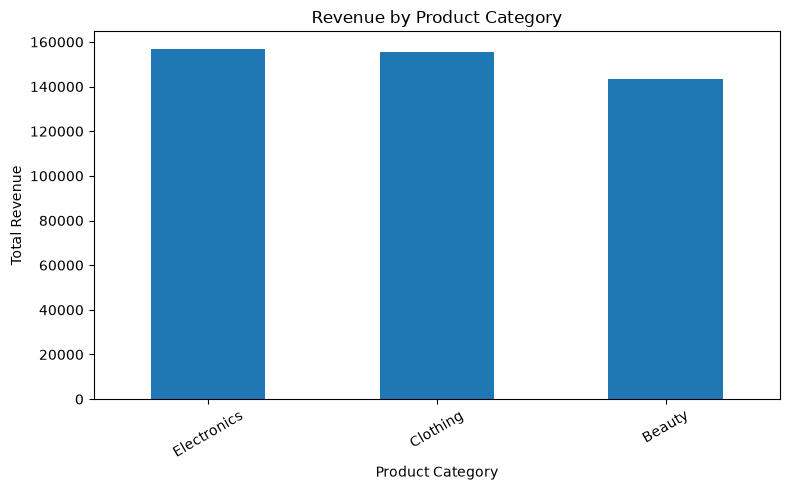

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

In [11]:

category_sales = df.groupby("Product Category")["Total Amount"].sum()
category_sales = category_sales.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(category_sales)


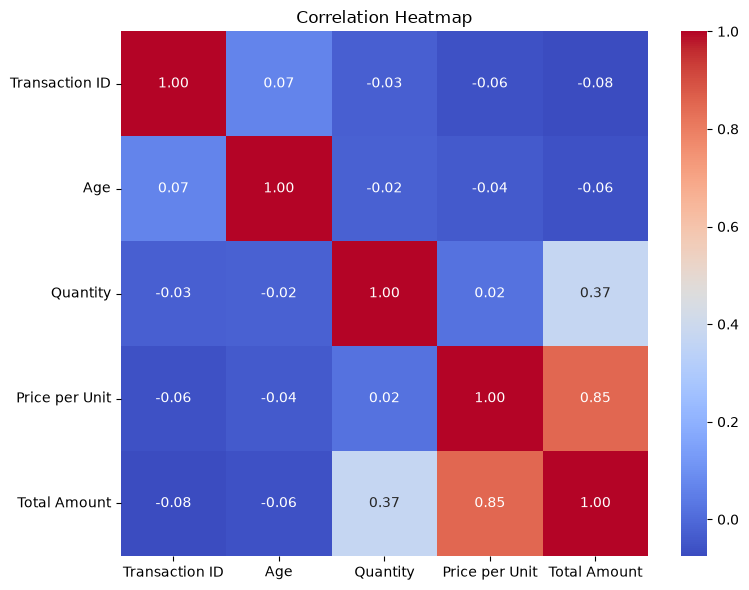

In [12]:

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


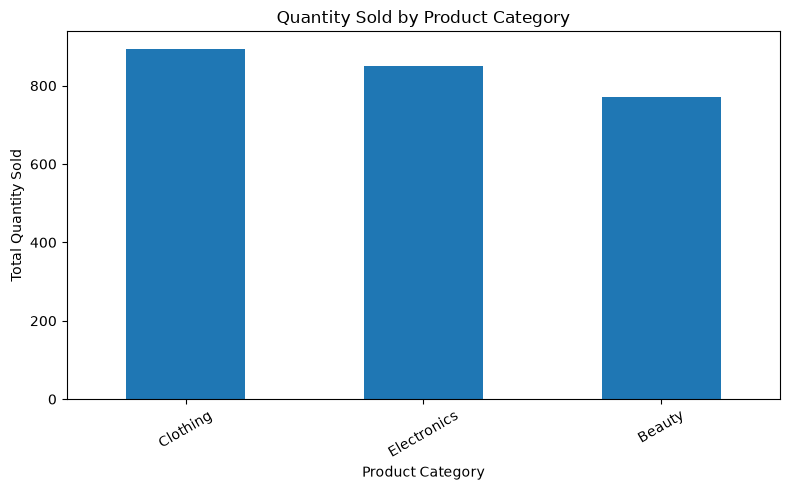

In [13]:

category_quantity = df.groupby("Product Category")["Quantity"].sum()
category_quantity = category_quantity.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
category_quantity.plot(kind="bar")
plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [14]:

print("Total Revenue:", df["Total Amount"].sum())
print("Average Transaction Amount:", df["Total Amount"].mean())
print("Highest Revenue Category:", category_sales.idxmax())
print("Lowest Revenue Category:", category_sales.idxmin())
print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Sales Quarter:", quarterly_sales.idxmax())
print("Total Transactions:", len(df))


Total Revenue: 456000
Average Transaction Amount: 456.0
Highest Revenue Category: Electronics
Lowest Revenue Category: Beauty
Highest Sales Month: 2023-05
Highest Sales Quarter: 2023Q4
Total Transactions: 1000



### Observation 1: Quarterly Sales
Quarterly sales analysis helps identify periods with higher and lower revenue and supports seasonal planning.

### Observation 2: Gender Analysis
The gender sales chart compares total spending across gender groups and can help businesses understand their customer segments.

### Observation 3: Age Distribution
The age distribution shows the age groups represented in the transactions and helps describe the customer base.

### Observation 4: Product Category Analysis
The category revenue chart identifies which product categories contribute the most and least revenue.

### Observation 5: Correlation Analysis
The heatmap shows the relationships between numerical variables. Correlation indicates association, not necessarily causation.

### Observation 6: Quantity Analysis
The quantity chart compares the number of units sold across categories and can support inventory planning.


## Conclusion

Exploratory Data Analysis was performed on the retail sales dataset to understand sales trends, customer characteristics, product category performance, and relationships between numerical variables. The analysis included descriptive statistics, monthly and quarterly sales charts, gender-based sales analysis, customer age distribution, category revenue, quantity sold, and a correlation heatmap.

### Business Recommendations

1. **Inventory planning:** Monitor revenue and quantity sold by category to plan stock levels and reduce stock shortages or excess inventory.
2. **Targeted marketing:** Use observed customer and purchasing patterns to develop suitable promotional campaigns.
3. **Sales monitoring:** Review monthly and quarterly sales regularly to identify changes in performance and plan promotions during weaker periods.

The findings can help support data-informed retail decisions. Further analysis with individual product names, costs, and profit data could provide deeper insights.